Proyek Akhir - Varian 1: Penentuan Jumlah Klaster Optimal (Metode Elbow)
Oleh: Ashfahani Hasyim
Tujuan: Melakukan eksplorasi, preprocessing data teks menjadi numerik, dan menentukan jumlah klaster (k) yang paling optimal menggunakan Metode Elbow.

Load Data Mentah & Inspeksi Awal

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load data mentah
df = pd.read_csv('laptop_price.csv', encoding='latin-1')
df.columns = df.columns.str.strip()

# 2. Hapus kolom yang tidak berguna (identifier)
if 'laptop_ID' in df.columns:
    df = df.drop(columns=['laptop_ID'])

print("Data berhasil dimuat! Shape:", df.shape)
print("\nCek Missing Value:\n", df.isnull().sum().max(), "nilai kosong ditemukan.")

Data berhasil dimuat! Shape: (1303, 12)

Cek Missing Value:
 0 nilai kosong ditemukan.


 Preprocessing

In [19]:
# 1. Parse RAM & Weight
df['Ram_GB'] = pd.to_numeric(df['Ram'].astype(str).str.replace('GB', '', regex=False).str.strip(), errors='coerce')
df['Ram_GB'] = df['Ram_GB'].fillna(df['Ram_GB'].median()).astype(int)

df['Weight_kg'] = pd.to_numeric(df['Weight'].astype(str).str.replace('kg', '', regex=False).str.strip(), errors='coerce')
df['Weight_kg'] = df['Weight_kg'].fillna(df['Weight_kg'].median())

# 2. Parse Memory (Storage, SSD, HDD)
def parse_memory(mem):
    mem = str(mem)
    total_gb = 0.0
    for val, unit in re.findall(r'(\d+\.?\d*)\s*(GB|TB)', mem):
        v = float(val)
        total_gb += v * 1024 if unit == 'TB' else v
    return total_gb, (1 if 'SSD' in mem else 0), (1 if 'HDD' in mem else 0)
df[['Storage_GB', 'Has_SSD', 'Has_HDD']] = df['Memory'].apply(lambda x: pd.Series(parse_memory(x)))

# 3. Parse CPU (GHz)
def parse_cpu(cpu):
    m = re.search(r'(\d+\.?\d*)\s*GHz', str(cpu))
    return float(m.group(1)) if m else np.nan
df['CPU_GHz'] = df['Cpu'].apply(parse_cpu)
df['CPU_GHz'] = df['CPU_GHz'].fillna(df['CPU_GHz'].median())

# 4. Parse ScreenResolution (Touch, IPS)
def parse_screen(res):
    res = str(res)
    return (1 if 'Touchscreen' in res else 0), (1 if 'IPS' in res else 0)
df[['Touchscreen', 'IPS']] = df['ScreenResolution'].apply(lambda x: pd.Series(parse_screen(x)))

print("Preprocessing Selesai! Kolom baru berhasil ditambahkan.")

Preprocessing Selesai! Kolom baru berhasil ditambahkan.


Pilih Fitur & Penskalaan

In [20]:
# 1. Pilih 9 fitur (TANPA Price_euros untuk menghindari data leakage)
fitur = [
    'Inches', 'Ram_GB', 'Weight_kg', 'CPU_GHz',
    'Storage_GB', 'Has_SSD', 'Has_HDD', 'Touchscreen', 'IPS'
]
X = df[fitur].copy()

# 2. Penskalaan (StandardScaler)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaling berhasil. Semua fitur sekarang berada di skala yang seimbang.")

Scaling berhasil. Semua fitur sekarang berada di skala yang seimbang.


Uji Coba K-Means & Hitung Inertia

In [21]:
inertia = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

print("Perhitungan Inertia selesai.")

Perhitungan Inertia selesai.


Visualisasi Grafik Elbow & Persentase

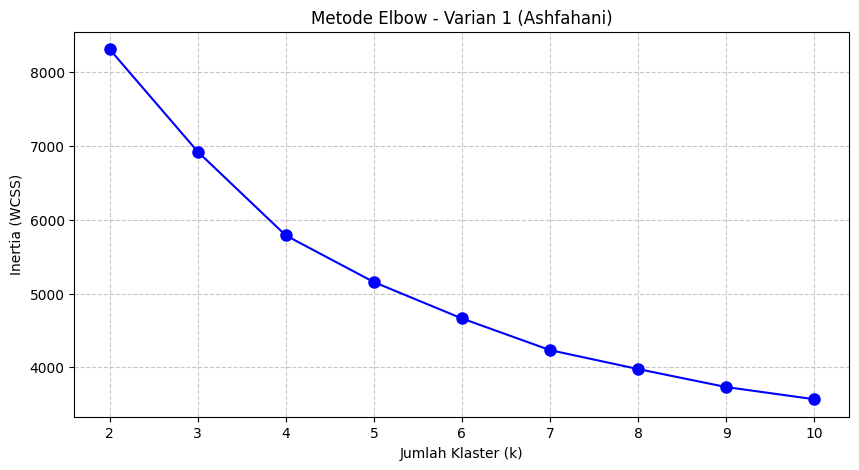

Persentase Penurunan Inertia Tiap K:
k=2 ke k=3: Turun 16.70%
k=3 ke k=4: Turun 16.40%
k=4 ke k=5: Turun 10.92%
k=5 ke k=6: Turun 9.56%
k=6 ke k=7: Turun 9.20%
k=7 ke k=8: Turun 6.06%
k=8 ke k=9: Turun 6.13%
k=9 ke k=10: Turun 4.42%


In [22]:
# 1. Plot Grafik Elbow
plt.figure(figsize=(10, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b', markersize=8)
plt.title('Metode Elbow - Varian 1 (Ashfahani)')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# 2. Tabel Persentase Penurunan
print("Persentase Penurunan Inertia Tiap K:")
for i in range(1, len(inertia)):
    drop = (inertia[i-1] - inertia[i]) / inertia[i-1] * 100
    print(f"k={K_range[i-1]} ke k={K_range[i]}: Turun {drop:.2f}%")

 Fit Model Final & Analisis Profil Klaster

In [23]:
# TENTUKAN K OPTIMAL BERDASARKAN GRAFIK DI ATAS
# (Melihat data historis, titik siku biasanya di k=4)
k_opt = 4

km_final = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
df['Cluster'] = km_final.fit_predict(X_scaled)

print(f"Model Final dilatih dengan k={k_opt}.\n")

# Profil Spesifikasi
profil = df.groupby('Cluster')[fitur].mean().round(2)
print("=== PROFIL RATA-RATA SPESIFIKASI ===")
print(profil)

# Validasi Bisnis (Harga & Tipe)
print("\n=== HARGA & TIPE DOMINAN ===")
for c in range(k_opt):
    sub = df[df['Cluster'] == c]
    harga = sub['Price_euros'].mean()
    tipe = sub['TypeName'].mode()[0]
    print(f"Klaster {c} (n={len(sub)}): Harga Rata-rata € {harga:.0f} | Tipe: {tipe}")

Model Final dilatih dengan k=4.

=== PROFIL RATA-RATA SPESIFIKASI ===
         Inches  Ram_GB  Weight_kg  CPU_GHz  Storage_GB  Has_SSD  Has_HDD  \
Cluster                                                                     
0         14.48    7.59       1.76     2.26      254.89     0.88     0.00   
1         15.62    5.76       2.19     2.23      874.23     0.03     0.98   
2         13.46    9.35       1.43     2.16      349.90     0.89     0.03   
3         16.47   14.17       2.93     2.64     1285.82     0.94     0.92   

         Touchscreen   IPS  
Cluster                     
0               0.00  0.29  
1               0.04  0.09  
2               1.00  0.47  
3               0.04  0.45  

=== HARGA & TIPE DOMINAN ===
Klaster 0 (n=539): Harga Rata-rata € 1089 | Tipe: Notebook
Klaster 1 (n=380): Harga Rata-rata € 652 | Tipe: Notebook
Klaster 2 (n=166): Harga Rata-rata € 1470 | Tipe: 2 in 1 Convertible
Klaster 3 (n=218): Harga Rata-rata € 1768 | Tipe: Gaming


Kesimpulan Analisis Elbow:
Berdasarkan visualisasi grafik Elbow dan tabel persentase penurunan, penurunan Inertia terbesar terjadi dari k=2 ke k=4. Namun, pada perpindahan dari k=4 ke k=5, persentase penurunan mulai melandai secara drastis (tidak sedrastis sebelumnya). Oleh karena itu, titik siku (elbow) berada di k=4. Jumlah ini dinilai paling optimal untuk membagi laptop ke dalam 4 segmen pasar tanpa membuat klaster menjadi terlalu spesifik.